# Phase-3 — TrustFin-SLM Baselines and Failure Analysis

**Paper:** *Trustworthy Small Language Models for Financial Tasks*

**Purpose of Phase-3:** establish reproducible small-language-model baselines, quantify the value of financial QLoRA adaptation and multi-task training, study prompt/sampling choices, profile efficiency, analyze failures/confidence, and **freeze one baseline checkpoint/configuration before Phase-4 protected-test evaluation**.

This notebook consumes the frozen **Phase-2.1 data contract** and intentionally uses **training + validation only**. It does **not** load FinQA test, FiQA test, FinBen-FOMC, or FinTrust during model/configuration selection.

### Experiments implemented

| ID | Experiment |
|---|---|
| E1 | Primary SLM zero-shot |
| E2 | Primary SLM few-shot |
| E3 | Primary SLM FinQA-only QLoRA |
| E4 | Primary SLM FiQA-only QLoRA |
| E5 | Primary SLM joint FinQA+FiQA QLoRA — dataset-balanced |
| E6 | Secondary SLM zero-shot |
| E7 | Secondary SLM few-shot |
| E8 | Secondary SLM joint FinQA+FiQA QLoRA — dataset-balanced |
| E9 | FinQA prompt/task-token comparison |
| E10 | FiQA prompt/task-token comparison |
| E11 | Joint-training sampling comparison — balanced vs natural |
| E12 | FinQA failure analysis |
| E13 | FiQA failure analysis |
| E14 | Confidence/error correlation |
| E15 | Efficiency profiling |
| E16 | Final validation comparison and Phase-3 freeze |

**Default models**

- Primary: `Qwen/Qwen3-1.7B`
- Secondary: `microsoft/Phi-4-mini-instruct`

The model IDs are configurable in one cell.

## How to run

1. **Complete Phase-2.1 first.** Its final report must show `PHASE-2.1 STATUS: PASS` and `READY FOR PHASE-3: True`.
2. Keep the Phase-2.1 artifact tree unchanged. The notebook expects:
   - `artifacts/phase2_1/datasets/train.jsonl`
   - `artifacts/phase2_1/datasets/validation.jsonl`
   - `artifacts/phase2_1/manifests/phase3_data_config.json`
   - `artifacts/phase2_1/manifests/phase4_eval_config.json`
   - `artifacts/phase2_1/manifests/dataset_registry.json`
3. Run on a CUDA GPU. A 40-GB A100 is suitable for the default QLoRA settings.
4. Set `TRUSTFIN_WORKSPACE` to the workspace containing `artifacts/phase2_1`, **or** edit `WORKSPACE_ROOT` in the configuration cell.
5. Start with `RUN_MODE="smoke"` and run the notebook top-to-bottom. Smoke mode executes all E1–E16 with small training/evaluation caps.
6. After smoke mode passes, set `RUN_MODE="full"` and rerun from a fresh kernel. Full mode uses the complete Phase-2.1 train/validation sets.
7. Do **not** point any Phase-3 cell to protected test data. Protected tests are reserved for Phase-4 after E16 freezes the configuration.
8. If a run is interrupted, rerun the notebook with `OVERWRITE=False`; completed adapters/predictions/metrics are reused where possible.
9. At the end, share the files listed in **“Outputs to share to freeze Phase-3.”**

> Research rule: Phase-3 selects the baseline using validation data only. Phase-4 is the first stage allowed to evaluate the frozen configuration on protected test sets.

## 0. Optional dependency installation

In [1]:
# Set to True only if the environment does not already contain these packages.
INSTALL_DEPS = False

if INSTALL_DEPS:
    import sys, subprocess
    packages = [
        "transformers>=4.51.0",
        "peft>=0.15.0",
        "bitsandbytes>=0.45.0",
        "accelerate>=1.2.0",
        "datasets>=3.0.0",
        "scikit-learn>=1.3.0",
        "scipy>=1.10.0",
        "pandas>=2.0.0",
        "matplotlib>=3.7.0",
        "psutil>=5.9.0",
    ]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-U", *packages])
    print("Dependencies installed. Restart the kernel once, then continue.")
else:
    print("INSTALL_DEPS=False — using the current environment.")

INSTALL_DEPS=False — using the current environment.


## 1. Imports, deterministic seed, and environment capture

In [2]:
from __future__ import annotations

import os, gc, re, json, math, time, random, hashlib, platform, inspect, importlib.util
from dataclasses import dataclass, asdict
from pathlib import Path
from collections import Counter, defaultdict
from typing import Any, Dict, List, Mapping, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, f1_score, roc_auc_score,
)

from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
    Trainer, TrainingArguments, DataCollatorForSeq2Seq,
)
from peft import (
    LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training,
)

SEED = 42

def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA runtime:", torch.version.cuda)
    print("BF16 supported:", torch.cuda.is_bf16_supported())

Python: 3.12.3
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA runtime: 13.0
BF16 supported: True


## 2. Global configuration

In [3]:
# ---------------- USER CONFIGURATION ----------------
RUN_MODE = os.environ.get("TRUSTFIN_RUN_MODE", "full").lower()  # "smoke" or "full"
OVERWRITE = False

PRIMARY_MODEL = "Qwen/Qwen3-1.7B"
SECONDARY_MODEL = "microsoft/Phi-4-mini-instruct"

# If TRUSTFIN_WORKSPACE is not set, these candidates are searched automatically.
DEFAULT_EXECUTED_PHASE2_WORKSPACE = Path(
    "/home/heet18/Downloads/Research Papers/trustfin_slm_workspace"
)
WORKSPACE_ROOT = Path(
    os.environ.get("TRUSTFIN_WORKSPACE", str(DEFAULT_EXECUTED_PHASE2_WORKSPACE))
).expanduser()

PHASE3_CONFIG_ENV = os.environ.get("TRUSTFIN_PHASE2_1_CONFIG", "")

# All 16 experiment IDs are implemented. Full mode runs all of them.
# Multi-PC sharding: set TRUSTFIN_EXPERIMENTS="E1,E2,E6,E7" (comma-separated)
# to run only a subset. Training adapters and eval metrics resume from disk,
# so shards are additive: run subsets on separate PCs, merge artifacts/, then
# run one consolidation pass with the full set.
_ALL_EXPERIMENTS = {
    "E1","E2","E3","E4","E5","E6","E7","E8",
    "E9","E10","E11","E12","E13","E14","E15","E16"
}
_experiments_env = os.environ.get("TRUSTFIN_EXPERIMENTS", "").strip()
RUN_EXPERIMENTS = (
    {x.strip().upper() for x in _experiments_env.split(",") if x.strip()}
    if _experiments_env else set(_ALL_EXPERIMENTS)
)
_unknown_experiments = RUN_EXPERIMENTS - _ALL_EXPERIMENTS
assert not _unknown_experiments, f"Unknown experiment IDs: {sorted(_unknown_experiments)}"
print("RUN_EXPERIMENTS:", sorted(RUN_EXPERIMENTS))

# QLoRA / sequence configuration
# NOTE (6 GB laptop GPU): default smoke cap was 1536, which OOMs during
# QLoRA backprop on the RTX 4050 (logits are seq x 151936 vocab in fp32).
# 768 works once frozen fp32 upcasts from kbit-prep are reverted (see cell 21).
# NOTE (6 GB laptop GPU): 3072 OOMs here — fp32 loss-path logits are seq x
# 151936 vocab (measured peaks: Qwen 4.53 GiB / Phi 4.88 GiB at seq 768;
# both exceed the 5.64 GiB ceiling above ~1300 tokens). 1024 keeps >=0.5 GiB
# margin for both models. Documented in docs/exp_3(b).md.
MAX_SEQ_LENGTH_FULL = 1024
MAX_SEQ_LENGTH_SMOKE = 768
MAX_SEQ_LENGTH = MAX_SEQ_LENGTH_SMOKE if RUN_MODE == "smoke" else MAX_SEQ_LENGTH_FULL

TRAIN_EPOCHS = 0.05 if RUN_MODE == "smoke" else 2.0
TRAIN_CAP_PER_DATASET = 64 if RUN_MODE == "smoke" else None
VAL_CAP_PER_DATASET = 20 if RUN_MODE == "smoke" else None

PER_DEVICE_TRAIN_BATCH = 1
GRAD_ACCUM = 8
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.03
MAX_GRAD_NORM = 1.0

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05

USE_4BIT = True
BNB_QUANT_TYPE = "nf4"
BNB_DOUBLE_QUANT = True

FINQA_MAX_NEW_TOKENS = 192
FIQA_MAX_NEW_TOKENS = 24
FEWSHOT_FINQA_N = 2
FEWSHOT_FIQA_N = 3

# Confidence is average generated-token probability exp(mean log p).
COMPUTE_CONFIDENCE = True

assert RUN_MODE in {"smoke", "full"}
print("RUN_MODE:", RUN_MODE)
print("WORKSPACE_ROOT:", WORKSPACE_ROOT)
print("MAX_SEQ_LENGTH:", MAX_SEQ_LENGTH)
print("TRAIN_EPOCHS:", TRAIN_EPOCHS)

RUN_EXPERIMENTS: ['E5']
RUN_MODE: full
WORKSPACE_ROOT: /home/heet18/Downloads/Research Papers/trustfin_slm_workspace
MAX_SEQ_LENGTH: 1024
TRAIN_EPOCHS: 2.0


## 3. Locate and validate the frozen Phase-2.1 contract

In [4]:
def locate_phase3_config() -> Path:
    candidates = []
    if PHASE3_CONFIG_ENV:
        candidates.append(Path(PHASE3_CONFIG_ENV).expanduser())
    candidates.extend([
        WORKSPACE_ROOT / "artifacts/phase2_1/manifests/phase3_data_config.json",
        Path.cwd() / "artifacts/phase2_1/manifests/phase3_data_config.json",
        Path.cwd().parent / "artifacts/phase2_1/manifests/phase3_data_config.json",
    ])
    for p in candidates:
        if p.exists():
            return p.resolve()

    # Conservative local search — only for the exact Phase-2.1 config filename.
    roots = [Path.cwd(), Path.cwd().parent]
    for root in roots:
        try:
            hits = list(root.glob("**/artifacts/phase2_1/manifests/phase3_data_config.json"))
        except Exception:
            hits = []
        if hits:
            return hits[0].resolve()

    raise FileNotFoundError(
        "Cannot locate phase3_data_config.json. Set TRUSTFIN_WORKSPACE or "
        "TRUSTFIN_PHASE2_1_CONFIG before running Phase-3."
    )

def read_json(path: Path):
    with Path(path).open("r", encoding="utf-8") as f:
        return json.load(f)

def read_jsonl(path: Path):
    rows = []
    with Path(path).open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))
    return rows

def write_json(path: Path, obj: Any):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)

def write_jsonl(path: Path, rows: Sequence[Mapping[str, Any]]):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(dict(r), ensure_ascii=False, default=str) + "\n")

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

PHASE3_CONFIG_PATH = locate_phase3_config()
PHASE3_DATA_CONFIG = read_json(PHASE3_CONFIG_PATH)
REGISTRY_PATH = Path(PHASE3_DATA_CONFIG["data_registry"])
REGISTRY = read_json(REGISTRY_PATH)

PHASE2_ROOT = REGISTRY_PATH.parents[2]   # .../artifacts/phase2_1
PHASE4_CONFIG_PATH = REGISTRY_PATH.parent / "phase4_eval_config.json"
PHASE4_DATA_CONFIG = read_json(PHASE4_CONFIG_PATH)

PHASE3_ROOT = WORKSPACE_ROOT / "artifacts/phase3"
if not WORKSPACE_ROOT.exists():
    # If an explicit workspace path was stale, anchor Phase-3 beside Phase-2.1.
    WORKSPACE_ROOT = PHASE2_ROOT.parents[1]
    PHASE3_ROOT = WORKSPACE_ROOT / "artifacts/phase3"

CHECKPOINT_DIR = PHASE3_ROOT / "checkpoints"
PRED_DIR = PHASE3_ROOT / "predictions"
METRIC_DIR = PHASE3_ROOT / "metrics"
ANALYSIS_DIR = PHASE3_ROOT / "analysis"
MANIFEST_DIR = PHASE3_ROOT / "manifests"
PLOT_DIR = PHASE3_ROOT / "plots"
for p in [CHECKPOINT_DIR, PRED_DIR, METRIC_DIR, ANALYSIS_DIR, MANIFEST_DIR, PLOT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Phase-2.1 config:", PHASE3_CONFIG_PATH)
print("Registry:", REGISTRY_PATH)
print("Phase-3 output root:", PHASE3_ROOT)

assert set(PHASE3_DATA_CONFIG["allowed_training_datasets"]) == {"FinQA", "FiQA"}
assert {"FinBen-FOMC", "FinTrust"}.issubset(
    set(PHASE3_DATA_CONFIG["forbidden_training_datasets"])
)
print("PASS: Phase-2.1 training policy is preserved.")

Phase-2.1 config: /home/heet18/Downloads/Research Papers/artifacts/phase2_1/manifests/phase3_data_config.json
Registry: /home/heet18/Downloads/Research Papers/artifacts/phase2_1/manifests/dataset_registry.json
Phase-3 output root: /home/heet18/Downloads/Research Papers/trustfin_slm_workspace/artifacts/phase3
PASS: Phase-2.1 training policy is preserved.


## 4. Load **only** train and validation artifacts

In [5]:
def resolve_artifact(key: str) -> Path:
    entry = REGISTRY["artifacts"][key]
    p = Path(entry["path"])
    if not p.exists():
        raise FileNotFoundError(f"Artifact missing: {key} -> {p}")
    if entry.get("sha256"):
        observed = sha256_file(p)
        assert observed == entry["sha256"], f"Hash mismatch for {key}"
    return p

TRAIN_PATH = resolve_artifact(PHASE3_DATA_CONFIG["train_artifact"])
VAL_PATH = resolve_artifact(PHASE3_DATA_CONFIG["validation_artifact"])

train_records = read_jsonl(TRAIN_PATH)
val_records = read_jsonl(VAL_PATH)

assert all(r["dataset"] in {"FinQA","FiQA"} for r in train_records)
assert all(r["dataset"] in {"FinQA","FiQA"} for r in val_records)
assert all(not r.get("metadata",{}).get("evaluation_only",False) for r in train_records)
assert all(not r.get("metadata",{}).get("evaluation_only",False) for r in val_records)

print("Train:", len(train_records), Counter(r["dataset"] for r in train_records))
print("Validation:", len(val_records), Counter(r["dataset"] for r in val_records))

# Full Phase-2.1 contract counts.
if RUN_MODE == "full":
    assert len(train_records) == 7073
    assert len(val_records) == 1000
    assert Counter(r["dataset"] for r in train_records) == {"FinQA":6251, "FiQA":822}
    assert Counter(r["dataset"] for r in val_records) == {"FinQA":883, "FiQA":117}

# Explicit guard: this notebook never resolves protected test artifact keys.
PROTECTED_KEYS = {"finqa_test","fiqa_test","finben_fomc_test","fintrust_registry"}
print("Protected artifacts intentionally NOT loaded:", sorted(PROTECTED_KEYS))

Train: 7073 Counter({'FinQA': 6251, 'FiQA': 822})
Validation: 1000 Counter({'FinQA': 883, 'FiQA': 117})
Protected artifacts intentionally NOT loaded: ['finben_fomc_test', 'finqa_test', 'fintrust_registry', 'fiqa_test']


## 5. Reproducibility snapshot

In [6]:
def package_version(name: str) -> Optional[str]:
    try:
        import importlib.metadata as im
        return im.version(name)
    except Exception:
        return None

ENVIRONMENT = {
    "created_unix": int(time.time()),
    "run_mode": RUN_MODE,
    "seed": SEED,
    "primary_model": PRIMARY_MODEL,
    "secondary_model": SECONDARY_MODEL,
    "phase2_1_registry": str(REGISTRY_PATH),
    "phase2_1_registry_sha256": sha256_file(REGISTRY_PATH),
    "train_sha256": sha256_file(TRAIN_PATH),
    "validation_sha256": sha256_file(VAL_PATH),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda_runtime": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "packages": {
        p: package_version(p)
        for p in ["transformers","peft","bitsandbytes","accelerate","datasets",
                  "scikit-learn","scipy","pandas","matplotlib"]
    },
    "training": {
        "max_seq_length": MAX_SEQ_LENGTH,
        "epochs": TRAIN_EPOCHS,
        "per_device_train_batch": PER_DEVICE_TRAIN_BATCH,
        "gradient_accumulation": GRAD_ACCUM,
        "learning_rate": LEARNING_RATE,
        "lora_r": LORA_R,
        "lora_alpha": LORA_ALPHA,
        "lora_dropout": LORA_DROPOUT,
        "use_4bit": USE_4BIT,
        "bnb_quant_type": BNB_QUANT_TYPE,
    },
}
ENVIRONMENT_PATH = MANIFEST_DIR / "environment.json"
write_json(ENVIRONMENT_PATH, ENVIRONMENT)
display(pd.json_normalize(ENVIRONMENT))

,created_unix,run_mode,seed,primary_model,secondary_model,phase2_1_registry,phase2_1_registry_sha256,train_sha256,validation_sha256,python,...,training.max_seq_length,training.epochs,training.per_device_train_batch,training.gradient_accumulation,training.learning_rate,training.lora_r,training.lora_alpha,training.lora_dropout,training.use_4bit,training.bnb_quant_type
0,1791614016,full,42,Qwen/Qwen3-1.7B,microsoft/Phi-4-mini-instruct,/home/heet18/Downloads/Research Papers/artifac...,e0c43a54add7323b60d139cac7be6a93694fad96d979b9...,9a62613461b70e2cf934ff22d60f2c868c1358c782ad1f...,354e8171eeb72d9e3ff20c667d7807d1803c4dcd68491c...,3.12.3,...,1024,2.0,1,8,0.0002,16,32,0.05,True,nf4


## 6. Utility: deterministic subsets, prompts, and few-shot exemplars

In [7]:
def cap_by_dataset(records, cap_per_dataset=None):
    if cap_per_dataset is None:
        return list(records)
    out = []
    for ds in ["FinQA","FiQA"]:
        subset = [r for r in records if r["dataset"] == ds]
        rng = random.Random(SEED + (0 if ds == "FinQA" else 1000))
        rng.shuffle(subset)
        out.extend(subset[:cap_per_dataset])
    return out

train_working = cap_by_dataset(train_records, TRAIN_CAP_PER_DATASET)
val_working = cap_by_dataset(val_records, VAL_CAP_PER_DATASET)

def select_fewshot_examples(dataset: str, n: int) -> List[Dict[str,Any]]:
    pool = sorted([r for r in train_records if r["dataset"] == dataset],
                  key=lambda r: r["record_id"])
    rng = random.Random(SEED + (17 if dataset == "FinQA" else 29))
    return rng.sample(pool, min(n, len(pool)))

FEWSHOT = {
    "FinQA": select_fewshot_examples("FinQA", FEWSHOT_FINQA_N),
    "FiQA": select_fewshot_examples("FiQA", FEWSHOT_FIQA_N),
}
FEWSHOT_MANIFEST = {
    k: [r["record_id"] for r in v] for k,v in FEWSHOT.items()
}
write_json(MANIFEST_DIR / "fewshot_manifest.json", FEWSHOT_MANIFEST)
print("Few-shot IDs:", FEWSHOT_MANIFEST)

TASK_TAG = {"FinQA":"<FINQA>", "FiQA":"<FIQA>"}

def user_content(record: Mapping[str,Any], variant: str = "canonical") -> str:
    ds = record["dataset"]
    instruction = record["instruction"].strip()
    inp = record["input"].strip()

    if ds == "FinQA":
        schema = "Return exactly two fields:\nPROGRAM: <valid FinQA program>\nANSWER: <final answer>"
    else:
        schema = "Return exactly:\nSENTIMENT_SCORE: <number from -1 to +1>"

    if variant == "canonical":
        return f"{TASK_TAG[ds]}\n{instruction}\n\n{inp}"
    if variant == "no_task_token":
        return f"{instruction}\n\n{inp}"
    if variant == "explicit_schema":
        return f"{TASK_TAG[ds]}\n{instruction}\n\n{schema}\n\n{inp}"
    raise ValueError(f"Unknown prompt variant: {variant}")

def chat_messages(
    record: Mapping[str,Any],
    variant: str = "canonical",
    exemplars: Optional[Sequence[Mapping[str,Any]]] = None,
) -> List[Dict[str,str]]:
    messages = [{"role":"system","content":record["system"]}]
    if exemplars:
        for ex in exemplars:
            messages.append({"role":"user","content":user_content(ex, variant)})
            messages.append({"role":"assistant","content":ex["target"]})
    messages.append({"role":"user","content":user_content(record, variant)})
    return messages

def render_chat(tokenizer, messages, add_generation_prompt=True) -> str:
    kwargs = dict(tokenize=False, add_generation_prompt=add_generation_prompt)
    # Qwen3 supports disabling explicit reasoning; other tokenizers may ignore it.
    try:
        return tokenizer.apply_chat_template(messages, enable_thinking=False, **kwargs)
    except TypeError:
        return tokenizer.apply_chat_template(messages, **kwargs)
    except Exception:
        # Fallback for tokenizers without a usable chat template.
        parts = []
        for m in messages:
            parts.append(f"{m['role'].upper()}:\n{m['content']}")
        if add_generation_prompt:
            parts.append("ASSISTANT:\n")
        return "\n\n".join(parts)

print("Working train:", Counter(r["dataset"] for r in train_working))
print("Working validation:", Counter(r["dataset"] for r in val_working))

Few-shot IDs: {'FinQA': ['finqa::DG/2008/page_86.pdf-1', 'finqa::AMT/2007/page_35.pdf-1'], 'FiQA': ['fiqa::train::15596', 'fiqa::train::16465', 'fiqa::train::17075']}
Working train: Counter({'FinQA': 6251, 'FiQA': 822})
Working validation: Counter({'FinQA': 883, 'FiQA': 117})


## 7. Load the official FinQA executor for validation metrics

In [8]:
def load_module_from_path(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, str(path))
    if spec is None or spec.loader is None:
        raise ImportError(f"Cannot import {name} from {path}")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

FINQA_EVALUATOR_PATH = Path(
    PHASE4_DATA_CONFIG["official_evaluators"]["FinQA_local"]
)
if not FINQA_EVALUATOR_PATH.exists():
    raise FileNotFoundError(
        f"Official FinQA evaluator not found: {FINQA_EVALUATOR_PATH}. "
        "Do not replace it with a custom executor; rerun Phase-2.1 in this workspace."
    )

FINQA_OFFICIAL = load_module_from_path("finqa_official_phase3", FINQA_EVALUATOR_PATH)

SOURCE_FINGERPRINTS = read_json(Path(REGISTRY["source_fingerprints"]))
FINQA_DEV_RAW_PATH = Path(SOURCE_FINGERPRINTS["FinQA"]["dev"]["path"])
if not FINQA_DEV_RAW_PATH.exists():
    raise FileNotFoundError(f"FinQA dev source missing: {FINQA_DEV_RAW_PATH}")

finqa_dev_raw = read_json(FINQA_DEV_RAW_PATH)
FINQA_DEV_TABLES = {str(item["id"]): item["table"] for item in finqa_dev_raw}

assert len(FINQA_DEV_TABLES) == 883
print("Official FinQA evaluator:", FINQA_EVALUATOR_PATH)
print("FinQA dev tables:", len(FINQA_DEV_TABLES))

Official FinQA evaluator: /home/heet18/Downloads/Research Papers/data/raw/finqa_official_evaluator/evaluate.py
FinQA dev tables: 883


## 8. Output parsers and task metrics

In [9]:
THINK_RE = re.compile(r"<think>.*?</think>", flags=re.I | re.S)

def clean_generation(text: str) -> str:
    text = THINK_RE.sub("", text or "")
    return text.strip()

def normalize_program(p: Any) -> str:
    return re.sub(r"\s+", "", str(p or "")).lower()

def parse_number_loose(x: Any) -> Optional[float]:
    if x is None:
        return None
    s = str(x).strip().lower().replace(",", "").replace("$", "")
    if not s or s in {"none","nan","n/a"}:
        return None
    percent = s.endswith("%")
    if percent:
        s = s[:-1].strip()
    try:
        v = float(s)
        return v / 100.0 if percent else v
    except Exception:
        return None

def loose_equal(a: Any, b: Any, atol=1e-4, rtol=1e-3) -> bool:
    if str(a).strip().lower() == str(b).strip().lower():
        return True
    na, nb = parse_number_loose(a), parse_number_loose(b)
    if na is None or nb is None:
        return False
    return bool(np.isclose(na, nb, atol=atol, rtol=rtol))

def parse_finqa_output(text: str) -> Dict[str,Any]:
    t = clean_generation(text)
    m_prog = re.search(r"PROGRAM\s*:\s*(.+?)(?=\n\s*ANSWER\s*:|$)", t, flags=re.I|re.S)
    m_ans = re.search(r"ANSWER\s*:\s*([^\n]+)", t, flags=re.I)
    program = m_prog.group(1).strip() if m_prog else None
    answer = m_ans.group(1).strip() if m_ans else None
    return {"program":program, "answer":answer, "parse_success":bool(program and answer)}

def parse_fiqa_output(text: str) -> Dict[str,Any]:
    t = clean_generation(text)
    m = re.search(r"SENTIMENT_SCORE\s*:\s*([-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?)", t, flags=re.I)
    val = None
    if m:
        try:
            val = float(m.group(1))
        except Exception:
            val = None
    if val is None:
        # Conservative fallback: use the first standalone number only if it is in the legal range.
        for s in re.findall(r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)", t):
            try:
                z = float(s)
                if -1.0 <= z <= 1.0:
                    val = z
                    break
            except Exception:
                pass
    return {"score":val, "parse_success":val is not None}

def execute_finqa_program(program: Optional[str], source_id: str) -> Tuple[bool,Any]:
    if not program:
        return False, None
    table = FINQA_DEV_TABLES.get(str(source_id))
    if table is None:
        return False, None
    try:
        tokens = FINQA_OFFICIAL.program_tokenization(program)
        invalid_flag, executed = FINQA_OFFICIAL.eval_program(tokens, table)
        return bool(invalid_flag == 0), executed
    except Exception:
        return False, None

def compute_finqa_metrics(df: pd.DataFrame) -> Dict[str,float]:
    if len(df) == 0:
        return {}
    return {
        "n": int(len(df)),
        "parse_success": float(df["parse_success"].mean()),
        "answer_accuracy": float(df["answer_correct"].mean()),
        "program_accuracy": float(df["program_correct"].mean()),
        "execution_accuracy": float(df["execution_correct"].mean()),
        "invalid_program_rate": float((~df["program_executable"]).mean()),
    }

def compute_fiqa_metrics(df: pd.DataFrame) -> Dict[str,float]:
    if len(df) == 0:
        return {}
    ok = df["pred_score"].notna()
    parse_rate = float(ok.mean())
    if ok.sum() == 0:
        return {"n":int(len(df)), "parse_success":parse_rate,
                "mae":float("nan"),"mse":float("nan"),"rmse":float("nan"),
                "r2":float("nan"),"pearson_r":float("nan")}
    y = df.loc[ok,"gold_score"].astype(float).to_numpy()
    p = np.clip(df.loc[ok,"pred_score"].astype(float).to_numpy(), -1, 1)
    mse = mean_squared_error(y,p)
    if len(y) >= 2 and np.std(y) > 0 and np.std(p) > 0:
        pr = float(pearsonr(y,p).statistic)
    else:
        pr = float("nan")
    return {
        "n": int(len(df)),
        "parse_success": parse_rate,
        "mae": float(mean_absolute_error(y,p)),
        "mse": float(mse),
        "rmse": float(math.sqrt(mse)),
        "r2": float(r2_score(y,p)) if len(y) >= 2 else float("nan"),
        "pearson_r": pr,
    }

## 9. Model loading, QLoRA setup, and memory utilities

In [10]:
def clear_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

def compute_dtype():
    if torch.cuda.is_available() and torch.cuda.is_bf16_supported():
        return torch.bfloat16
    return torch.float16

def quantization_config():
    if not USE_4BIT:
        return None
    return BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type=BNB_QUANT_TYPE,
        bnb_4bit_use_double_quant=BNB_DOUBLE_QUANT,
        bnb_4bit_compute_dtype=compute_dtype(),
    )

def load_tokenizer(model_id: str):
    # trust_remote_code=False: Phi-4-mini's bundled modeling_phi3.py imports
    # SlidingWindowCache, removed in transformers 5.x; native Phi3 works.
    tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=False)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "right"
    tok.truncation_side = "left"
    return tok

def prepare_kbit_training_lowmem(model, use_gradient_checkpointing: bool = True):
    """Mirror of peft's prepare_model_for_kbit_training, minus the fatal step.

    peft upcasts every non-4bit fp16/bf16 parameter to fp32, which on
    Phi-4-mini means a transient +2.29 GiB for the tied embed/lm_head
    (200064 x 3072 x 4 bytes) -- impossible on a 6 GB GPU (baseline 4.45 GiB).
    The original flow restored those large frozen tensors to the shipped
    dtype right after the upcast anyway, so skipping the upcast for tensors
    over 50M params yields byte-identical final dtypes with no transient:
      - >50M frozen tensors: stay bf16/fp16  (peft: fp32 -> restored to bf16)
      - other non-4bit fp16/bf16 (layernorms): fp32  (same as peft)
      - Params4bit: untouched                      (same as peft)
    Freezing, enable_input_require_grads, gradient checkpointing and the
    allocator release replicate peft exactly.
    """
    for param in model.parameters():
        param.requires_grad = False
    for param in model.parameters():
        if ((param.dtype == torch.float16) or (param.dtype == torch.bfloat16)) \
                and param.__class__.__name__ != "Params4bit":
            if param.numel() > 50_000_000:
                continue
            param.data = param.data.to(torch.float32)
    if use_gradient_checkpointing:
        if hasattr(model, "enable_input_require_grads"):
            model.enable_input_require_grads()
        gc_kwargs = {}
        if "gradient_checkpointing_kwargs" in inspect.signature(
            model.gradient_checkpointing_enable
        ).parameters:
            gc_kwargs["gradient_checkpointing_kwargs"] = {}
        model.gradient_checkpointing_enable(**gc_kwargs)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return model

def load_base_model(model_id: str, for_training: bool = False):
    kwargs = dict(
        trust_remote_code=False,
        device_map="auto",
    )
    if USE_4BIT:
        kwargs["quantization_config"] = quantization_config()
    else:
        kwargs["torch_dtype"] = compute_dtype()
    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    model.config.use_cache = not for_training
    if for_training and USE_4BIT:
        if torch.cuda.is_available():
            print(f"[mem] before prepare: allocated={torch.cuda.memory_allocated()/2**30:.2f} GiB "
                  f"free={torch.cuda.mem_get_info()[0]/2**30:.2f} GiB", flush=True)
        model = prepare_kbit_training_lowmem(model, use_gradient_checkpointing=True)
        # prepare_model_for_kbit_training upcasts frozen embeddings/lm_head to
        # fp32 (+1.1 GiB on 100k-vocab models such as Phi-4-mini). They stay
        # frozen during QLoRA, so restore the shipped dtype to fit 6 GB GPUs.
        dtype = compute_dtype()
        restored = []
        for _name, _p in model.named_parameters():
            if _p.dtype == torch.float32 and not _p.requires_grad and _p.numel() > 10_000_000:
                _p.data = _p.data.to(dtype)
                restored.append(_name)
        if restored:
            print("Restored frozen tensors to", dtype, "->", restored)
        if torch.cuda.is_available():
            print(f"[mem] after prepare: allocated={torch.cuda.memory_allocated()/2**30:.2f} GiB", flush=True)
    return model

def discover_lora_targets(model) -> List[str]:
    preferred = [
        "q_proj","k_proj","v_proj","o_proj","qkv_proj",
        "gate_proj","up_proj","down_proj","gate_up_proj",
        "fc1","fc2",
    ]
    names = [n for n,_ in model.named_modules()]
    found = [suffix for suffix in preferred if any(n.endswith(suffix) for n in names)]
    if found:
        return found
    # Fallback: LoRA on leaf linear-like modules except lm_head.
    suffixes = set()
    for name,module in model.named_modules():
        cls = module.__class__.__name__.lower()
        if ("linear" in cls) and not name.endswith("lm_head"):
            suffixes.add(name.split(".")[-1])
    if not suffixes:
        raise RuntimeError("Could not discover LoRA target modules.")
    return sorted(suffixes)

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def load_inference_model(model_id: str, adapter_path: Optional[Path] = None):
    tokenizer = load_tokenizer(model_id)
    model = load_base_model(model_id, for_training=False)
    if adapter_path is not None:
        model = PeftModel.from_pretrained(model, str(adapter_path))
    model.eval()
    return model, tokenizer

## 10. Tokenization audit before training

In [11]:
def prompt_and_target_lengths(model_id: str, sample_records: Sequence[Mapping[str,Any]], n=300):
    tok = load_tokenizer(model_id)
    rng = random.Random(SEED)
    sample = list(sample_records)
    if len(sample) > n:
        sample = rng.sample(sample, n)
    rows = []
    for r in sample:
        prompt = render_chat(tok, chat_messages(r), add_generation_prompt=True)
        full = prompt + r["target"] + (tok.eos_token or "")
        rows.append({
            "dataset":r["dataset"],
            "prompt_tokens":len(tok(prompt, add_special_tokens=False)["input_ids"]),
            "full_tokens":len(tok(full, add_special_tokens=False)["input_ids"]),
        })
    return pd.DataFrame(rows)

length_audit = prompt_and_target_lengths(PRIMARY_MODEL, train_records)
display(length_audit.groupby("dataset")["full_tokens"].describe(percentiles=[.5,.9,.95,.99]))
print("Estimated truncation rate @", MAX_SEQ_LENGTH, ":",
      float((length_audit["full_tokens"] > MAX_SEQ_LENGTH).mean()))

,count,mean,std,min,50%,90%,95%,99%,max
dataset,,,,,,,,,
FiQA,28.0,130.607143,8.727731,117.0,128.0,142.0,145.25,149.92,151.0
FinQA,272.0,1130.415441,352.739317,430.0,1084.0,1545.5,1708.20,2208.98,3330.0


Estimated truncation rate @ 1024 : 0.5333333333333333


## 11. Causal-SFT tokenization and balanced/natural sampling

In [12]:
def select_training_records(dataset_mode: str, sampling: str = "natural") -> List[Dict[str,Any]]:
    if dataset_mode == "finqa":
        records = [r for r in train_records if r["dataset"] == "FinQA"]
    elif dataset_mode == "fiqa":
        records = [r for r in train_records if r["dataset"] == "FiQA"]
    elif dataset_mode == "joint":
        records = list(train_records)
    else:
        raise ValueError(dataset_mode)

    if TRAIN_CAP_PER_DATASET is not None:
        if dataset_mode == "joint":
            records = cap_by_dataset(records, TRAIN_CAP_PER_DATASET)
        else:
            rng = random.Random(SEED)
            rng.shuffle(records)
            records = records[:TRAIN_CAP_PER_DATASET]

    if dataset_mode != "joint" or sampling == "natural":
        return records

    if sampling != "balanced":
        raise ValueError(sampling)

    # Fixed-size 50/50 resampling with replacement. Same number of examples/epoch
    # as the natural joint pool, so E5 vs E11 keeps optimizer-step budget comparable.
    groups = {
        ds:[r for r in records if r["dataset"] == ds] for ds in ["FinQA","FiQA"]
    }
    n_total = len(records)
    n_finqa = n_total // 2
    n_fiqa = n_total - n_finqa
    rng = random.Random(SEED)
    out = (
        [rng.choice(groups["FinQA"]) for _ in range(n_finqa)]
        + [rng.choice(groups["FiQA"]) for _ in range(n_fiqa)]
    )
    rng.shuffle(out)
    return out

def tokenize_sft_records(records, tokenizer, variant="canonical"):
    def encode_one(r):
        prompt = render_chat(
            tokenizer,
            chat_messages(r, variant=variant),
            add_generation_prompt=True,
        )
        target = r["target"] + (tokenizer.eos_token or "")
        prompt_ids = tokenizer(
            prompt, add_special_tokens=False, truncation=False
        )["input_ids"]
        target_ids = tokenizer(
            target, add_special_tokens=False, truncation=False
        )["input_ids"]

        # Always preserve the complete target; trim the oldest prompt tokens if needed.
        target_ids = target_ids[:MAX_SEQ_LENGTH]
        room = max(0, MAX_SEQ_LENGTH - len(target_ids))
        prompt_ids = prompt_ids[-room:] if room else []

        input_ids = prompt_ids + target_ids
        labels = [-100] * len(prompt_ids) + list(target_ids)
        attention_mask = [1] * len(input_ids)
        return {
            "input_ids":input_ids,
            "attention_mask":attention_mask,
            "labels":labels,
        }

    # NOTE: raw SFT records contain mixed-type fields (e.g. target_answer is
    # float for most FinQA rows but str for some, including literal "no"),
    # which pyarrow cannot infer. Encode first, then build the Dataset from
    # the integer-only token arrays (input_ids / attention_mask / labels).
    encoded = [encode_one(r) for r in records]
    return Dataset.from_list(encoded)

## 12. QLoRA training function with resumable artifacts

In [13]:
TRAINING_RUNS = {}

def training_args(output_dir: Path, epochs: float):
    kwargs = dict(
        output_dir=str(output_dir),
        num_train_epochs=epochs,
        per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH,
        gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        warmup_ratio=WARMUP_RATIO,
        max_grad_norm=MAX_GRAD_NORM,
        logging_steps=10,
        save_strategy="no",
        report_to=[],
        remove_unused_columns=False,
        fp16=(compute_dtype() == torch.float16),
        bf16=(compute_dtype() == torch.bfloat16),
        gradient_checkpointing=True,
        optim="paged_adamw_8bit" if USE_4BIT else "adamw_torch",
        seed=SEED,
        data_seed=SEED,
    )
    sig = inspect.signature(TrainingArguments.__init__)
    if "eval_strategy" in sig.parameters:
        kwargs["eval_strategy"] = "no"
    elif "evaluation_strategy" in sig.parameters:
        kwargs["evaluation_strategy"] = "no"
    return TrainingArguments(**kwargs)

def train_qlora(
    exp_id: str,
    model_id: str,
    dataset_mode: str,
    sampling: str,
    prompt_variant: str = "canonical",
) -> Path:
    exp_dir = CHECKPOINT_DIR / exp_id
    adapter_cfg = exp_dir / "adapter_config.json"
    run_meta_path = METRIC_DIR / f"{exp_id}_training.json"

    if adapter_cfg.exists() and run_meta_path.exists() and not OVERWRITE:
        TRAINING_RUNS[exp_id] = read_json(run_meta_path)
        print(f"{exp_id}: reusing existing adapter -> {exp_dir}")
        return exp_dir

    clear_memory()
    train_rows = select_training_records(dataset_mode, sampling)
    print(f"{exp_id}: train rows =", len(train_rows), Counter(r["dataset"] for r in train_rows))

    tokenizer = load_tokenizer(model_id)
    if torch.cuda.is_available():
        print(f"[mem] {exp_id} pre-load: allocated={torch.cuda.memory_allocated()/2**30:.2f} GiB "
              f"free={torch.cuda.mem_get_info()[0]/2**30:.2f} GiB", flush=True)
    model = load_base_model(model_id, for_training=True)
    targets = discover_lora_targets(model)
    print("LoRA targets:", targets)

    lora_cfg = LoraConfig(
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        task_type="CAUSAL_LM",
        target_modules=targets,
    )
    model = get_peft_model(model, lora_cfg)
    total_params, trainable_params = count_parameters(model)

    tokenized = tokenize_sft_records(train_rows, tokenizer, prompt_variant)
    collator = DataCollatorForSeq2Seq(
        tokenizer=tokenizer,
        model=None,
        padding=True,
        label_pad_token_id=-100,
        return_tensors="pt",
    )

    args = training_args(exp_dir / "trainer_tmp", TRAIN_EPOCHS)
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=tokenized,
        data_collator=collator,
    )

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    result = trainer.train()
    elapsed = time.perf_counter() - t0
    peak_gb = (
        torch.cuda.max_memory_allocated() / (1024**3)
        if torch.cuda.is_available() else float("nan")
    )

    exp_dir.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(exp_dir)
    tokenizer.save_pretrained(exp_dir)

    meta = {
        "experiment":exp_id,
        "model_id":model_id,
        "dataset_mode":dataset_mode,
        "sampling":sampling,
        "prompt_variant":prompt_variant,
        "train_rows":len(train_rows),
        "train_counts":dict(Counter(r["dataset"] for r in train_rows)),
        "epochs":TRAIN_EPOCHS,
        "total_parameters":int(total_params),
        "trainable_parameters":int(trainable_params),
        "trainable_fraction":float(trainable_params/max(total_params,1)),
        "train_seconds":float(elapsed),
        "peak_vram_gb":float(peak_gb),
        "trainer_metrics":{k:float(v) if isinstance(v,(int,float)) else v
                           for k,v in result.metrics.items()},
        "adapter_path":str(exp_dir.resolve()),
    }
    write_json(run_meta_path, meta)
    TRAINING_RUNS[exp_id] = meta

    del trainer, model, tokenizer, tokenized
    clear_memory()
    return exp_dir

## 13. Deterministic generation with token-level confidence

In [14]:
@torch.inference_mode()
def generate_one(
    model,
    tokenizer,
    record: Mapping[str,Any],
    variant: str = "canonical",
    exemplars: Optional[Sequence[Mapping[str,Any]]] = None,
    compute_confidence: bool = COMPUTE_CONFIDENCE,
) -> Dict[str,Any]:
    messages = chat_messages(record, variant=variant, exemplars=exemplars)
    prompt_text = render_chat(tokenizer, messages, add_generation_prompt=True)
    batch = tokenizer(prompt_text, return_tensors="pt", truncation=True,
                      max_length=MAX_SEQ_LENGTH)
    device = next(model.parameters()).device
    batch = {k:v.to(device) for k,v in batch.items()}

    max_new = FINQA_MAX_NEW_TOKENS if record["dataset"] == "FinQA" else FIQA_MAX_NEW_TOKENS
    t0 = time.perf_counter()
    out = model.generate(
        **batch,
        max_new_tokens=max_new,
        do_sample=False,
        return_dict_in_generate=True,
        output_scores=compute_confidence,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    elapsed = time.perf_counter() - t0

    prompt_len = batch["input_ids"].shape[1]
    gen_ids = out.sequences[:, prompt_len:]
    text = tokenizer.decode(gen_ids[0], skip_special_tokens=True)
    n_gen = int(gen_ids.shape[1])

    mean_logprob = float("nan")
    confidence = float("nan")
    if compute_confidence and n_gen > 0 and getattr(out, "scores", None):
        try:
            trans = model.compute_transition_scores(
                out.sequences, out.scores, normalize_logits=True
            )
            # transition scores correspond to generated positions.
            vals = trans[0, -n_gen:].detach().float().cpu().numpy()
            vals = vals[np.isfinite(vals)]
            if len(vals):
                mean_logprob = float(np.mean(vals))
                confidence = float(np.exp(np.clip(mean_logprob, -50, 0)))
        except Exception:
            pass

    return {
        "raw_output":clean_generation(text),
        "prompt_tokens":int(prompt_len),
        "generated_tokens":n_gen,
        "latency_seconds":float(elapsed),
        "tokens_per_second":float(n_gen/elapsed) if elapsed > 0 else float("nan"),
        "mean_logprob":mean_logprob,
        "confidence":confidence,
    }

## 14. Unified validation evaluator

In [15]:
def evaluate_records_with_loaded_model(
    exp_id: str,
    model,
    tokenizer,
    records: Sequence[Mapping[str,Any]],
    shot_mode: str = "zero",
    prompt_variant: str = "canonical",
    prediction_suffix: str = "",
) -> Tuple[pd.DataFrame, Dict[str,Any]]:
    rows = []
    for idx, r in enumerate(records, 1):
        exemplars = None
        if shot_mode == "few":
            exemplars = FEWSHOT[r["dataset"]]

        g = generate_one(
            model, tokenizer, r,
            variant=prompt_variant,
            exemplars=exemplars,
        )
        base = {
            "experiment":exp_id,
            "record_id":r["record_id"],
            "source_id":r["source_id"],
            "dataset":r["dataset"],
            "task":r["task"],
            "shot_mode":shot_mode,
            "prompt_variant":prompt_variant,
            **g,
        }

        if r["dataset"] == "FinQA":
            parsed = parse_finqa_output(g["raw_output"])
            executable, executed = execute_finqa_program(parsed["program"], str(r["source_id"]))
            base.update({
                "pred_program":parsed["program"],
                "pred_answer":parsed["answer"],
                "parse_success":parsed["parse_success"],
                "gold_program":r["gold_program"],
                "gold_answer":r["target_answer"],
                "program_correct":normalize_program(parsed["program"]) == normalize_program(r["gold_program"]),
                "answer_correct":loose_equal(parsed["answer"], r["target_answer"]),
                "program_executable":bool(executable),
                "executed_answer":executed,
                "execution_correct":bool(executable and loose_equal(executed, r["target_answer"])),
            })
        else:
            parsed = parse_fiqa_output(g["raw_output"])
            base.update({
                "pred_score":parsed["score"],
                "gold_score":float(r["target_answer"]),
                "parse_success":parsed["parse_success"],
                "absolute_error":(
                    abs(float(parsed["score"]) - float(r["target_answer"]))
                    if parsed["score"] is not None else float("nan")
                ),
            })
        rows.append(base)
        if idx % 50 == 0:
            print(f"{exp_id}: evaluated {idx}/{len(records)}")

    df = pd.DataFrame(rows)
    metrics = {}
    finqa_df = df[df["dataset"]=="FinQA"].copy()
    fiqa_df = df[df["dataset"]=="FiQA"].copy()
    if len(finqa_df):
        metrics["FinQA"] = compute_finqa_metrics(finqa_df)
    if len(fiqa_df):
        metrics["FiQA"] = compute_fiqa_metrics(fiqa_df)

    metrics["Efficiency"] = {
        "n":int(len(df)),
        "mean_latency_seconds":float(df["latency_seconds"].mean()),
        "median_latency_seconds":float(df["latency_seconds"].median()),
        "tokens_per_second":float(
            df["generated_tokens"].sum() / max(df["latency_seconds"].sum(),1e-9)
        ),
        "mean_prompt_tokens":float(df["prompt_tokens"].mean()),
        "mean_generated_tokens":float(df["generated_tokens"].mean()),
    }

    suffix = f"_{prediction_suffix}" if prediction_suffix else ""
    pred_path = PRED_DIR / f"{exp_id}{suffix}.csv"
    metric_path = METRIC_DIR / f"{exp_id}{suffix}.json"
    df.to_csv(pred_path, index=False)
    write_json(metric_path, metrics)
    return df, metrics

def run_eval_experiment(
    exp_id: str,
    model_id: str,
    adapter_path: Optional[Path] = None,
    shot_mode: str = "zero",
    prompt_variant: str = "canonical",
    records: Optional[Sequence[Mapping[str,Any]]] = None,
    suffix: str = "",
):
    records = list(records if records is not None else val_working)
    pred_name = f"{exp_id}_{suffix}.csv" if suffix else f"{exp_id}.csv"
    metric_name = f"{exp_id}_{suffix}.json" if suffix else f"{exp_id}.json"
    pred_path = PRED_DIR / pred_name
    metric_path = METRIC_DIR / metric_name

    if pred_path.exists() and metric_path.exists() and not OVERWRITE:
        print(f"{exp_id}{('/'+suffix) if suffix else ''}: using cached evaluation.")
        return pd.read_csv(pred_path), read_json(metric_path)

    clear_memory()
    model, tokenizer = load_inference_model(model_id, adapter_path)
    df, metrics = evaluate_records_with_loaded_model(
        exp_id, model, tokenizer, records,
        shot_mode=shot_mode,
        prompt_variant=prompt_variant,
        prediction_suffix=suffix,
    )
    del model, tokenizer
    clear_memory()
    if torch.cuda.is_available():
        print(f"[mem] {exp_id} after eval free: allocated={torch.cuda.memory_allocated()/2**30:.2f} GiB", flush=True)
    return df, metrics

## 15. Experiment registry

In [16]:
EXPERIMENTS = {
    "E1":{"name":"Primary zero-shot","model":PRIMARY_MODEL},
    "E2":{"name":"Primary few-shot","model":PRIMARY_MODEL},
    "E3":{"name":"Primary FinQA-only QLoRA","model":PRIMARY_MODEL},
    "E4":{"name":"Primary FiQA-only QLoRA","model":PRIMARY_MODEL},
    "E5":{"name":"Primary joint balanced QLoRA","model":PRIMARY_MODEL},
    "E6":{"name":"Secondary zero-shot","model":SECONDARY_MODEL},
    "E7":{"name":"Secondary few-shot","model":SECONDARY_MODEL},
    "E8":{"name":"Secondary joint balanced QLoRA","model":SECONDARY_MODEL},
    "E9":{"name":"FinQA prompt comparison","model":PRIMARY_MODEL},
    "E10":{"name":"FiQA prompt comparison","model":PRIMARY_MODEL},
    "E11":{"name":"Joint sampling comparison","model":PRIMARY_MODEL},
    "E12":{"name":"FinQA failure analysis"},
    "E13":{"name":"FiQA failure analysis"},
    "E14":{"name":"Confidence/error correlation"},
    "E15":{"name":"Efficiency profiling"},
    "E16":{"name":"Final validation comparison and freeze"},
}
write_json(MANIFEST_DIR / "experiment_plan.json", EXPERIMENTS)
display(pd.DataFrame([{"experiment":k,**v} for k,v in EXPERIMENTS.items()]))

,experiment,name,model
0,E1,Primary zero-shot,Qwen/Qwen3-1.7B
1,E2,Primary few-shot,Qwen/Qwen3-1.7B
2,E3,Primary FinQA-only QLoRA,Qwen/Qwen3-1.7B
3,E4,Primary FiQA-only QLoRA,Qwen/Qwen3-1.7B
4,E5,Primary joint balanced QLoRA,Qwen/Qwen3-1.7B
5,E6,Secondary zero-shot,microsoft/Phi-4-mini-instruct
6,E7,Secondary few-shot,microsoft/Phi-4-mini-instruct
7,E8,Secondary joint balanced QLoRA,microsoft/Phi-4-mini-instruct
8,E9,FinQA prompt comparison,Qwen/Qwen3-1.7B
9,E10,FiQA prompt comparison,Qwen/Qwen3-1.7B


## E1 — Primary SLM zero-shot

In [17]:
RESULTS = {}
if "E1" in RUN_EXPERIMENTS:
    E1_pred, E1_metrics = run_eval_experiment(
        "E1", PRIMARY_MODEL, shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E1"] = E1_metrics
    display(pd.json_normalize(E1_metrics, sep="."))

## E2 — Primary SLM few-shot

In [18]:
if "E2" in RUN_EXPERIMENTS:
    E2_pred, E2_metrics = run_eval_experiment(
        "E2", PRIMARY_MODEL, shot_mode="few", prompt_variant="canonical"
    )
    RESULTS["E2"] = E2_metrics
    display(pd.json_normalize(E2_metrics, sep="."))

## E3 — Primary SLM FinQA-only QLoRA

In [19]:
E3_adapter = None
if "E3" in RUN_EXPERIMENTS:
    E3_adapter = train_qlora(
        "E3", PRIMARY_MODEL, dataset_mode="finqa",
        sampling="natural", prompt_variant="canonical"
    )
    E3_pred, E3_metrics = run_eval_experiment(
        "E3", PRIMARY_MODEL, adapter_path=E3_adapter,
        shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E3"] = E3_metrics
    display(pd.json_normalize(E3_metrics, sep="."))

## E4 — Primary SLM FiQA-only QLoRA

In [20]:
E4_adapter = None
if "E4" in RUN_EXPERIMENTS:
    E4_adapter = train_qlora(
        "E4", PRIMARY_MODEL, dataset_mode="fiqa",
        sampling="natural", prompt_variant="canonical"
    )
    E4_pred, E4_metrics = run_eval_experiment(
        "E4", PRIMARY_MODEL, adapter_path=E4_adapter,
        shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E4"] = E4_metrics
    display(pd.json_normalize(E4_metrics, sep="."))

## E5 — Primary SLM joint FinQA+FiQA QLoRA (dataset-balanced)

In [21]:
E5_adapter = None
if "E5" in RUN_EXPERIMENTS:
    E5_adapter = train_qlora(
        "E5", PRIMARY_MODEL, dataset_mode="joint",
        sampling="balanced", prompt_variant="canonical"
    )
    E5_pred, E5_metrics = run_eval_experiment(
        "E5", PRIMARY_MODEL, adapter_path=E5_adapter,
        shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E5"] = E5_metrics
    display(pd.json_normalize(E5_metrics, sep="."))

E5: train rows =

 7073 Counter({'FiQA': 3537, 'FinQA': 3536})


[mem] E5 pre-load: allocated=0.00 GiB free=5.55 GiB


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

[mem] before prepare: allocated=1.26 GiB free=3.41 GiB


...

E5: evaluated 900/1000


E5: evaluated 950/1000


E5: evaluated 1000/1000


[mem] E5 after eval free: allocated=0.60 GiB


,FinQA.n,FinQA.parse_success,FinQA.answer_accuracy,FinQA.program_accuracy,FinQA.execution_accuracy,FinQA.invalid_program_rate,FiQA.n,FiQA.parse_success,FiQA.mae,FiQA.mse,FiQA.rmse,FiQA.r2,FiQA.pearson_r,Efficiency.n,Efficiency.mean_latency_seconds,Efficiency.median_latency_seconds,Efficiency.tokens_per_second,Efficiency.mean_prompt_tokens,Efficiency.mean_generated_tokens
0,883,1.0,0.375991,0.611552,0.674972,-1.996602,117,1.0,0.130103,0.03749,0.193624,0.730069,0.873217,1000,1.179324,1.161947,24.500481,821.593,28.894


## E6 — Secondary SLM zero-shot

In [22]:
if "E6" in RUN_EXPERIMENTS:
    E6_pred, E6_metrics = run_eval_experiment(
        "E6", SECONDARY_MODEL, shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E6"] = E6_metrics
    display(pd.json_normalize(E6_metrics, sep="."))

## E7 — Secondary SLM few-shot

In [23]:
if "E7" in RUN_EXPERIMENTS:
    E7_pred, E7_metrics = run_eval_experiment(
        "E7", SECONDARY_MODEL, shot_mode="few", prompt_variant="canonical"
    )
    RESULTS["E7"] = E7_metrics
    display(pd.json_normalize(E7_metrics, sep="."))

## E8 — Secondary SLM joint FinQA+FiQA QLoRA (dataset-balanced)

In [24]:
E8_adapter = None
if "E8" in RUN_EXPERIMENTS:
    E8_adapter = train_qlora(
        "E8", SECONDARY_MODEL, dataset_mode="joint",
        sampling="balanced", prompt_variant="canonical"
    )
    E8_pred, E8_metrics = run_eval_experiment(
        "E8", SECONDARY_MODEL, adapter_path=E8_adapter,
        shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E8"] = E8_metrics
    display(pd.json_normalize(E8_metrics, sep="."))

## E9 — FinQA prompt/task-token comparison

This experiment uses the **E5 frozen adapter** and changes only inference prompt formatting:

- `canonical`: task token + original Phase-2.1 instruction/input
- `no_task_token`: removes `<FINQA>`
- `explicit_schema`: keeps the task token and explicitly states the required output schema

The comparison uses FinQA validation only.

In [25]:
E9_ROWS = []
if "E9" in RUN_EXPERIMENTS:
    if E5_adapter is None:
        E5_adapter = CHECKPOINT_DIR / "E5"
    assert (E5_adapter / "adapter_config.json").exists(), "Run E5 first."

    finqa_val = [r for r in val_working if r["dataset"]=="FinQA"]
    for variant in ["canonical","no_task_token","explicit_schema"]:
        pred, met = run_eval_experiment(
            "E9", PRIMARY_MODEL, adapter_path=E5_adapter,
            records=finqa_val, prompt_variant=variant, suffix=variant,
        )
        m = met["FinQA"]
        E9_ROWS.append({"variant":variant, **m})
    E9_DF = pd.DataFrame(E9_ROWS)
    E9_DF.to_csv(ANALYSIS_DIR/"E9_finqa_prompt_ablation.csv", index=False)
    display(E9_DF)

## E10 — FiQA prompt/task-token comparison

Same frozen E5 adapter; FiQA validation only.

In [26]:
E10_ROWS = []
if "E10" in RUN_EXPERIMENTS:
    if E5_adapter is None:
        E5_adapter = CHECKPOINT_DIR / "E5"
    assert (E5_adapter / "adapter_config.json").exists(), "Run E5 first."

    fiqa_val = [r for r in val_working if r["dataset"]=="FiQA"]
    for variant in ["canonical","no_task_token","explicit_schema"]:
        pred, met = run_eval_experiment(
            "E10", PRIMARY_MODEL, adapter_path=E5_adapter,
            records=fiqa_val, prompt_variant=variant, suffix=variant,
        )
        m = met["FiQA"]
        E10_ROWS.append({"variant":variant, **m})
    E10_DF = pd.DataFrame(E10_ROWS)
    E10_DF.to_csv(ANALYSIS_DIR/"E10_fiqa_prompt_ablation.csv", index=False)
    display(E10_DF)

## E11 — Joint-training sampling comparison

E5 is the **balanced** reference. E11 trains a same-budget **natural/proportional** joint adapter using the identical base model and hyperparameters. This isolates the effect of sampling.

In [27]:
E11_adapter = None
if "E11" in RUN_EXPERIMENTS:
    E11_adapter = train_qlora(
        "E11", PRIMARY_MODEL, dataset_mode="joint",
        sampling="natural", prompt_variant="canonical"
    )
    E11_pred, E11_metrics = run_eval_experiment(
        "E11", PRIMARY_MODEL, adapter_path=E11_adapter,
        shot_mode="zero", prompt_variant="canonical"
    )
    RESULTS["E11"] = E11_metrics

    rows = []
    for exp in ["E5","E11"]:
        mp = METRIC_DIR / f"{exp}.json"
        if mp.exists():
            m = read_json(mp)
            rows.append({
                "experiment":exp,
                "sampling":"balanced" if exp=="E5" else "natural",
                "finqa_execution_accuracy":m.get("FinQA",{}).get("execution_accuracy"),
                "finqa_program_accuracy":m.get("FinQA",{}).get("program_accuracy"),
                "fiqa_mae":m.get("FiQA",{}).get("mae"),
                "fiqa_r2":m.get("FiQA",{}).get("r2"),
            })
    E11_DF = pd.DataFrame(rows)
    E11_DF.to_csv(ANALYSIS_DIR/"E11_sampling_ablation.csv", index=False)
    display(E11_DF)

## 16. Consolidate E1–E11 validation metrics

In [28]:
def flatten_experiment_metric(exp: str, m: Mapping[str,Any]) -> Dict[str,Any]:
    row = {"experiment":exp}
    for section, vals in m.items():
        if isinstance(vals, Mapping):
            for k,v in vals.items():
                row[f"{section}.{k}"] = v
    return row

# Load any cached metrics even after notebook restart.
for exp in ["E1","E2","E3","E4","E5","E6","E7","E8","E11"]:
    p = METRIC_DIR / f"{exp}.json"
    if p.exists():
        RESULTS[exp] = read_json(p)

METRICS_DF = pd.DataFrame([
    flatten_experiment_metric(exp,m) for exp,m in RESULTS.items()
]).sort_values("experiment")

METRICS_DF.to_csv(METRIC_DIR/"phase3_validation_metrics.csv", index=False)
display(METRICS_DF)

,experiment,FinQA.n,FinQA.parse_success,FinQA.answer_accuracy,FinQA.program_accuracy,FinQA.execution_accuracy,FinQA.invalid_program_rate,FiQA.n,FiQA.parse_success,FiQA.mae,FiQA.mse,FiQA.rmse,FiQA.r2,FiQA.pearson_r,Efficiency.n,Efficiency.mean_latency_seconds,Efficiency.median_latency_seconds,Efficiency.tokens_per_second,Efficiency.mean_prompt_tokens,Efficiency.mean_generated_tokens
1,E1,883,0.013590,0.004530,0.000000,0.000000,-1.000000,117,1.000000,0.500521,0.387028,0.622116,-1.786614,0.684000,1000,3.398192,4.185188,44.070198,821.593,149.759
2,E2,883,0.000000,0.000000,0.000000,0.000000,-1.000000,117,1.000000,0.185068,0.073331,0.270797,0.472014,0.805849,1000,3.083744,3.682240,48.537105,950.305,149.676
3,E3,883,1.000000,0.389581,0.624009,0.680634,-1.988675,117,0.606838,0.504724,0.356620,0.597177,-1.839797,0.469402,1000,1.187762,1.163553,24.697705,821.593,29.335
4,E4,883,0.000000,0.000000,0.000000,0.000000,-1.000000,117,1.000000,0.129453,0.038199,0.195447,0.724963,0.863956,1000,2.345942,1.536160,22.550430,821.593,52.902
0,E5,883,1.000000,0.375991,0.611552,0.674972,-1.996602,117,1.000000,0.130103,0.037490,0.193624,0.730069,0.873217,1000,1.179324,1.161947,24.500481,821.593,28.894
5,E6,883,0.028313,0.000000,0.000000,0.000000,-1.000000,117,1.000000,0.381479,0.200574,0.447855,-0.444136,0.814589,1000,3.336588,3.811465,43.955080,772.516,146.660
6,E7,883,0.144960,0.005663,0.033975,0.039638,-1.109853,117,1.000000,0.325239,0.164063,0.405047,-0.181259,0.806334,1000,3.534298,4.383968,42.973460,946.034,151.881


## Candidate-selection rule used by E12–E16

Only **jointly adapted variants of the pre-declared primary model** are eligible as the Phase-4 backbone:

- E5: primary, balanced
- E11: primary, natural

E8 remains a cross-family baseline to test whether adaptation gains are model-specific; it is not used to switch the proposed method's backbone after validation. Task-specific E3/E4 are valuable controls but cannot represent a single multi-task backbone.

A pre-declared validation score is used only for operational checkpoint selection:

\[
S_{FinQA}=rac{AnswerAcc+ProgramAcc+ExecutionAcc}{3}
\]

\[
S_{FiQA}=1-rac{MAE}{2}
\]

because FiQA scores are bounded to \([-1,1]\), so the maximum absolute error is 2.

\[
S_{macro}=rac{S_{FinQA}+S_{FiQA}}{2}
\]

All component metrics are still reported separately; the paper should not hide task-specific trade-offs behind this scalar.

In [29]:
JOINT_CANDIDATES = {
    # Phase-4 backbone candidates are intentionally restricted to the pre-declared
    # primary model. E8 remains a cross-family robustness/comparison baseline.
    "E5":{"model_id":PRIMARY_MODEL, "adapter":CHECKPOINT_DIR/"E5", "sampling":"balanced"},
    "E11":{"model_id":PRIMARY_MODEL, "adapter":CHECKPOINT_DIR/"E11", "sampling":"natural"},
}

def macro_selection_score(metrics: Mapping[str,Any]) -> float:
    f = metrics.get("FinQA",{})
    q = metrics.get("FiQA",{})
    needed_f = [f.get("answer_accuracy"), f.get("program_accuracy"), f.get("execution_accuracy")]
    mae = q.get("mae")
    if any(v is None or not np.isfinite(v) for v in needed_f):
        return float("-inf")
    if mae is None or not np.isfinite(mae):
        return float("-inf")
    finqa_score = float(np.mean(needed_f))
    fiqa_score = float(np.clip(1.0 - float(mae)/2.0, 0.0, 1.0))
    return 0.5*finqa_score + 0.5*fiqa_score

CANDIDATE_ROWS = []
for exp,cfg in JOINT_CANDIDATES.items():
    mp = METRIC_DIR/f"{exp}.json"
    if mp.exists() and (cfg["adapter"]/ "adapter_config.json").exists():
        m = read_json(mp)
        CANDIDATE_ROWS.append({
            "experiment":exp,
            "model_id":cfg["model_id"],
            "sampling":cfg["sampling"],
            "selection_score":macro_selection_score(m),
            "finqa_answer_accuracy":m["FinQA"]["answer_accuracy"],
            "finqa_program_accuracy":m["FinQA"]["program_accuracy"],
            "finqa_execution_accuracy":m["FinQA"]["execution_accuracy"],
            "fiqa_mae":m["FiQA"]["mae"],
            "fiqa_r2":m["FiQA"]["r2"],
        })

CANDIDATE_DF = pd.DataFrame(CANDIDATE_ROWS).sort_values(
    "selection_score", ascending=False
) if CANDIDATE_ROWS else pd.DataFrame()

display(CANDIDATE_DF)

if len(CANDIDATE_DF):
    BEST_JOINT_EXP = str(CANDIDATE_DF.iloc[0]["experiment"])
    BEST_JOINT_CFG = JOINT_CANDIDATES[BEST_JOINT_EXP]
    print("Current best joint candidate:", BEST_JOINT_EXP)
else:
    BEST_JOINT_EXP = None
    BEST_JOINT_CFG = None
    print("No complete joint candidate yet.")

,experiment,model_id,sampling,selection_score,finqa_answer_accuracy,finqa_program_accuracy,finqa_execution_accuracy,fiqa_mae,fiqa_r2
0,E5,Qwen/Qwen3-1.7B,balanced,0.74456,0.375991,0.611552,0.674972,0.130103,0.730069


Current best joint candidate: E5


## E12 — FinQA failure analysis

In [30]:
if "E12" in RUN_EXPERIMENTS:
    assert BEST_JOINT_EXP is not None, "Complete E5/E8/E11 first."
    p = PRED_DIR / f"{BEST_JOINT_EXP}.csv"
    best_pred = pd.read_csv(p)
    fin = best_pred[best_pred["dataset"]=="FinQA"].copy()

    def failure_type(r):
        if not bool(r["parse_success"]):
            return "parse_failure"
        if not bool(r["program_executable"]):
            return "invalid_program"
        if not bool(r["execution_correct"]) and bool(r["answer_correct"]):
            return "answer_right_program_wrong"
        if bool(r["execution_correct"]) and not bool(r["answer_correct"]):
            return "program_right_answer_wrong"
        if not bool(r["program_correct"]) and bool(r["execution_correct"]):
            return "alternate_program_same_execution"
        if not bool(r["execution_correct"]):
            return "reasoning_execution_error"
        if not bool(r["program_correct"]):
            return "program_exact_mismatch"
        return "correct"

    fin["failure_type"] = fin.apply(failure_type, axis=1)
    E12_SUMMARY = (
        fin.groupby("failure_type").size().reset_index(name="count")
           .sort_values("count", ascending=False)
    )
    E12_SUMMARY["rate"] = E12_SUMMARY["count"]/len(fin)
    fin.to_csv(ANALYSIS_DIR/"E12_finqa_failure_cases.csv", index=False)
    E12_SUMMARY.to_csv(ANALYSIS_DIR/"E12_finqa_failure_summary.csv", index=False)
    display(E12_SUMMARY)

## E13 — FiQA failure analysis

In [31]:
if "E13" in RUN_EXPERIMENTS:
    assert BEST_JOINT_EXP is not None
    p = PRED_DIR / f"{BEST_JOINT_EXP}.csv"
    best_pred = pd.read_csv(p)
    fi = best_pred[best_pred["dataset"]=="FiQA"].copy()

    fi["abs_error"] = (fi["pred_score"] - fi["gold_score"]).abs()
    fi["error_band"] = pd.cut(
        fi["abs_error"],
        bins=[-1e-9,0.1,0.25,0.5,1.0,float("inf")],
        labels=["<=0.10","0.10-0.25","0.25-0.50","0.50-1.00",">1.00"],
    )
    E13_SUMMARY = (
        fi.groupby("error_band", observed=False).size().reset_index(name="count")
    )
    E13_SUMMARY["rate"] = E13_SUMMARY["count"]/max(len(fi),1)
    fi.sort_values("abs_error", ascending=False).to_csv(
        ANALYSIS_DIR/"E13_fiqa_failure_cases.csv", index=False
    )
    E13_SUMMARY.to_csv(ANALYSIS_DIR/"E13_fiqa_failure_summary.csv", index=False)
    display(E13_SUMMARY)
    display(fi.sort_values("abs_error", ascending=False).head(20))

## E14 — Confidence/error correlation

Confidence is derived from the model's own generated-token likelihood:

\[
confidence = \exp\left(rac{1}{T}\sum_t \log p(y_t|y_{<t},x)ight)
\]

This is **diagnostic only** in Phase-3. No abstention threshold is selected here; calibration and selective prediction belong to Phase-4.

In [32]:
if "E14" in RUN_EXPERIMENTS:
    assert BEST_JOINT_EXP is not None
    best_pred = pd.read_csv(PRED_DIR/f"{BEST_JOINT_EXP}.csv")
    conf_rows = []

    fin = best_pred[best_pred["dataset"]=="FinQA"].copy()
    fin = fin[np.isfinite(fin["confidence"])]
    if len(fin):
        correctness = fin["execution_correct"].astype(int).to_numpy()
        conf = fin["confidence"].astype(float).to_numpy()
        auc = float("nan")
        if len(np.unique(correctness)) == 2:
            auc = float(roc_auc_score(correctness, conf))
        sp = float(spearmanr(conf, correctness).statistic) if len(fin) >= 3 else float("nan")
        conf_rows.append({
            "dataset":"FinQA",
            "n":len(fin),
            "target":"execution_correct",
            "spearman_confidence_target":sp,
            "roc_auc_confidence":auc,
        })

    fi = best_pred[best_pred["dataset"]=="FiQA"].copy()
    fi = fi[np.isfinite(fi["confidence"]) & np.isfinite(fi["pred_score"])]
    if len(fi):
        err = np.abs(fi["pred_score"].astype(float) - fi["gold_score"].astype(float))
        conf = fi["confidence"].astype(float).to_numpy()
        sp = float(spearmanr(conf, -err).statistic) if len(fi) >= 3 else float("nan")
        pr = float(pearsonr(conf, -err).statistic) if len(fi) >= 3 and np.std(conf)>0 and np.std(err)>0 else float("nan")
        conf_rows.append({
            "dataset":"FiQA",
            "n":len(fi),
            "target":"negative_absolute_error",
            "spearman_confidence_target":sp,
            "pearson_confidence_target":pr,
        })

    E14_DF = pd.DataFrame(conf_rows)
    E14_DF.to_csv(ANALYSIS_DIR/"E14_confidence_error_correlation.csv", index=False)
    display(E14_DF)

    # Reliability-style diagnostic bins for the frozen candidate.
    diag = []
    for ds in ["FinQA","FiQA"]:
        d = best_pred[(best_pred["dataset"]==ds) & np.isfinite(best_pred["confidence"])].copy()
        if len(d) < 5:
            continue
        d["confidence_bin"] = pd.qcut(
            d["confidence"], q=min(5,len(d)), duplicates="drop"
        )
        if ds == "FinQA":
            g = d.groupby("confidence_bin", observed=False).agg(
                n=("record_id","size"),
                mean_confidence=("confidence","mean"),
                quality=("execution_correct","mean"),
            ).reset_index()
        else:
            d["quality"] = 1 - np.clip(
                (d["pred_score"]-d["gold_score"]).abs()/2.0, 0, 1
            )
            g = d.groupby("confidence_bin", observed=False).agg(
                n=("record_id","size"),
                mean_confidence=("confidence","mean"),
                quality=("quality","mean"),
            ).reset_index()
        g["dataset"] = ds
        diag.append(g.astype({"confidence_bin":str}))
    E14_BINS = pd.concat(diag, ignore_index=True) if diag else pd.DataFrame()
    E14_BINS.to_csv(ANALYSIS_DIR/"E14_confidence_bins.csv", index=False)
    display(E14_BINS)

## E15 — Efficiency profiling

In [33]:
def load_training_meta(exp):
    p = METRIC_DIR/f"{exp}_training.json"
    return read_json(p) if p.exists() else {}

E15_ROWS = []
if "E15" in RUN_EXPERIMENTS:
    for exp in ["E1","E2","E3","E4","E5","E6","E7","E8","E11"]:
        mp = METRIC_DIR/f"{exp}.json"
        if not mp.exists():
            continue
        m = read_json(mp)
        tm = load_training_meta(exp)
        E15_ROWS.append({
            "experiment":exp,
            "model_id":EXPERIMENTS.get(exp,{}).get("model"),
            "trainable_parameters":tm.get("trainable_parameters",0 if exp in {"E1","E2","E6","E7"} else None),
            "total_parameters":tm.get("total_parameters"),
            "train_seconds":tm.get("train_seconds",0.0),
            "peak_vram_gb_training":tm.get("peak_vram_gb"),
            "mean_inference_latency_s":m.get("Efficiency",{}).get("mean_latency_seconds"),
            "tokens_per_second":m.get("Efficiency",{}).get("tokens_per_second"),
            "mean_prompt_tokens":m.get("Efficiency",{}).get("mean_prompt_tokens"),
            "mean_generated_tokens":m.get("Efficiency",{}).get("mean_generated_tokens"),
        })
    E15_DF = pd.DataFrame(E15_ROWS)
    E15_DF.to_csv(ANALYSIS_DIR/"E15_efficiency_profile.csv", index=False)
    display(E15_DF)

## E16 — Final validation comparison and freeze

The notebook now freezes:

1. the best **primary-model joint** backbone among E5/E11,
2. the best FinQA prompt variant from E9,
3. the best FiQA prompt variant from E10,
4. the complete hyperparameter/environment/data fingerprints.

This freeze file is the only configuration Phase-4 should consume for the baseline backbone.

In [34]:
def choose_finqa_prompt():
    p = ANALYSIS_DIR/"E9_finqa_prompt_ablation.csv"
    if not p.exists():
        return "canonical", None
    d = pd.read_csv(p)
    # Execution is primary; program accuracy breaks ties; answer accuracy breaks remaining ties.
    d = d.sort_values(
        ["execution_accuracy","program_accuracy","answer_accuracy"],
        ascending=False
    )
    return str(d.iloc[0]["variant"]), d.iloc[0].to_dict()

def choose_fiqa_prompt():
    p = ANALYSIS_DIR/"E10_fiqa_prompt_ablation.csv"
    if not p.exists():
        return "canonical", None
    d = pd.read_csv(p)
    # MAE is primary; R2 breaks ties.
    d = d.sort_values(["mae","r2"], ascending=[True,False])
    return str(d.iloc[0]["variant"]), d.iloc[0].to_dict()

if "E16" in RUN_EXPERIMENTS:
    # Refresh candidate table in case cached metrics were loaded.
    rows = []
    for exp,cfg in JOINT_CANDIDATES.items():
        mp = METRIC_DIR/f"{exp}.json"
        ap = cfg["adapter"]
        if mp.exists() and (ap/"adapter_config.json").exists():
            m = read_json(mp)
            rows.append({
                "experiment":exp,
                "model_id":cfg["model_id"],
                "adapter_path":str(ap.resolve()),
                "sampling":cfg["sampling"],
                "selection_score":macro_selection_score(m),
                "finqa_answer_accuracy":m["FinQA"]["answer_accuracy"],
                "finqa_program_accuracy":m["FinQA"]["program_accuracy"],
                "finqa_execution_accuracy":m["FinQA"]["execution_accuracy"],
                "fiqa_mae":m["FiQA"]["mae"],
                "fiqa_mse":m["FiQA"]["mse"],
                "fiqa_r2":m["FiQA"]["r2"],
                "fiqa_pearson_r":m["FiQA"]["pearson_r"],
            })
    final_candidates = pd.DataFrame(rows).sort_values("selection_score", ascending=False)
    assert len(final_candidates) > 0, "No joint adapted candidates available to freeze."
    final_candidates.to_csv(METRIC_DIR/"E16_joint_candidate_comparison.csv", index=False)
    display(final_candidates)

    winner = final_candidates.iloc[0].to_dict()
    finqa_prompt, finqa_prompt_row = choose_finqa_prompt()
    fiqa_prompt, fiqa_prompt_row = choose_fiqa_prompt()

    FREEZE = {
        "phase":"Phase-3",
        "status":"FROZEN" if RUN_MODE=="full" else "SMOKE_ONLY_NOT_FROZEN",
        "run_mode":RUN_MODE,
        "selection_rule":{
            "eligible_experiments":["E5","E11"],
            "finqa_score":"mean(answer_accuracy, program_accuracy, execution_accuracy)",
            "fiqa_score":"1 - MAE/2, clipped to [0,1]",
            "macro_score":"mean(FinQA_score, FiQA_score)",
        },
        "winner":winner,
        "prompt_policy":{
            "FinQA":finqa_prompt,
            "FiQA":fiqa_prompt,
            "FinQA_validation_row":finqa_prompt_row,
            "FiQA_validation_row":fiqa_prompt_row,
        },
        "data":{
            "phase2_1_registry":str(REGISTRY_PATH.resolve()),
            "registry_sha256":sha256_file(REGISTRY_PATH),
            "train_path":str(TRAIN_PATH.resolve()),
            "train_sha256":sha256_file(TRAIN_PATH),
            "validation_path":str(VAL_PATH.resolve()),
            "validation_sha256":sha256_file(VAL_PATH),
        },
        "environment_manifest":str(ENVIRONMENT_PATH.resolve()),
        "important":[
            "No protected Phase-4 test set was used for model selection.",
            "Phase-4 must not change the frozen baseline backbone after seeing protected-test results.",
            "Calibration/abstention thresholds must be fitted on validation only.",
        ],
    }
    FREEZE_PATH = MANIFEST_DIR/"phase3_freeze.json"
    write_json(FREEZE_PATH, FREEZE)
    print("Freeze manifest:", FREEZE_PATH)
    print("Status:", FREEZE["status"])
    print("Winner:", FREEZE["winner"]["experiment"], FREEZE["winner"]["model_id"])
    print("Prompts:", FREEZE["prompt_policy"])

## 17. Research figures for Phase-3

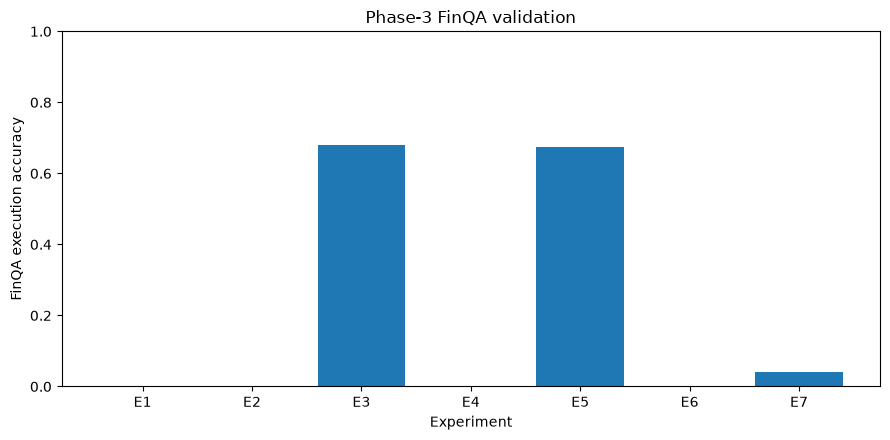

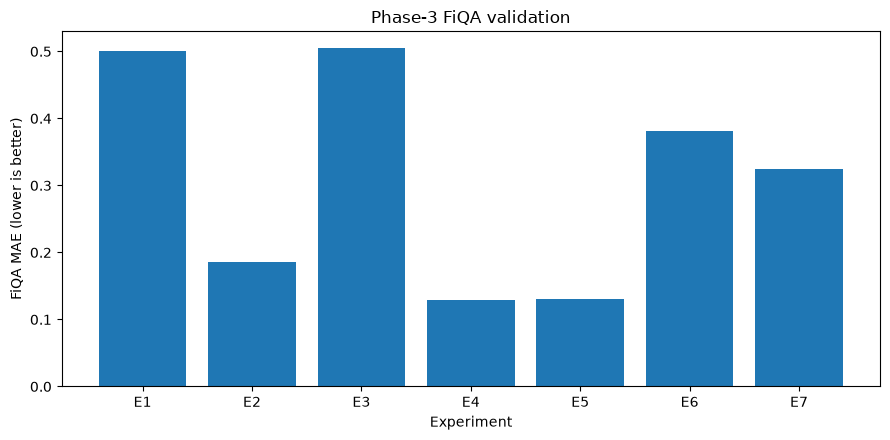

In [35]:
# Figures are generated only from validation metrics.
if (METRIC_DIR/"phase3_validation_metrics.csv").exists():
    d = pd.read_csv(METRIC_DIR/"phase3_validation_metrics.csv")

    if "FinQA.execution_accuracy" in d.columns:
        x = d.dropna(subset=["FinQA.execution_accuracy"])
        if len(x):
            fig, ax = plt.subplots(figsize=(9,4.5))
            ax.bar(x["experiment"], x["FinQA.execution_accuracy"])
            ax.set_ylabel("FinQA execution accuracy")
            ax.set_xlabel("Experiment")
            ax.set_title("Phase-3 FinQA validation")
            ax.set_ylim(0,1)
            fig.tight_layout()
            fig.savefig(PLOT_DIR/"finqa_execution_accuracy.png", dpi=180)
            plt.show()

    if "FiQA.mae" in d.columns:
        x = d.dropna(subset=["FiQA.mae"])
        if len(x):
            fig, ax = plt.subplots(figsize=(9,4.5))
            ax.bar(x["experiment"], x["FiQA.mae"])
            ax.set_ylabel("FiQA MAE (lower is better)")
            ax.set_xlabel("Experiment")
            ax.set_title("Phase-3 FiQA validation")
            fig.tight_layout()
            fig.savefig(PLOT_DIR/"fiqa_mae.png", dpi=180)
            plt.show()

## 18. Phase-3 completion gates

In [36]:
EXPECTED_EXPERIMENT_OUTPUTS = {
    "E1":METRIC_DIR/"E1.json",
    "E2":METRIC_DIR/"E2.json",
    "E3":METRIC_DIR/"E3.json",
    "E4":METRIC_DIR/"E4.json",
    "E5":METRIC_DIR/"E5.json",
    "E6":METRIC_DIR/"E6.json",
    "E7":METRIC_DIR/"E7.json",
    "E8":METRIC_DIR/"E8.json",
    "E9":ANALYSIS_DIR/"E9_finqa_prompt_ablation.csv",
    "E10":ANALYSIS_DIR/"E10_fiqa_prompt_ablation.csv",
    "E11":ANALYSIS_DIR/"E11_sampling_ablation.csv",
    "E12":ANALYSIS_DIR/"E12_finqa_failure_summary.csv",
    "E13":ANALYSIS_DIR/"E13_fiqa_failure_summary.csv",
    "E14":ANALYSIS_DIR/"E14_confidence_error_correlation.csv",
    "E15":ANALYSIS_DIR/"E15_efficiency_profile.csv",
    "E16":MANIFEST_DIR/"phase3_freeze.json",
}

gate_rows = []
for exp,path in EXPECTED_EXPERIMENT_OUTPUTS.items():
    gate_rows.append({
        "experiment":exp,
        "output":str(path),
        "exists":path.exists(),
    })

GATES_DF = pd.DataFrame(gate_rows)
display(GATES_DF)

all_outputs_exist = bool(GATES_DF["exists"].all())
freeze_exists = (MANIFEST_DIR/"phase3_freeze.json").exists()
freeze_status = None
if freeze_exists:
    freeze_status = read_json(MANIFEST_DIR/"phase3_freeze.json").get("status")

PHASE3_COMPLETE = (
    all_outputs_exist
    and RUN_MODE == "full"
    and freeze_status == "FROZEN"
)

COMPLETION_REPORT = {
    "phase3_complete":PHASE3_COMPLETE,
    "run_mode":RUN_MODE,
    "all_E1_to_E16_outputs_exist":all_outputs_exist,
    "freeze_status":freeze_status,
    "gates":gate_rows,
    "protected_test_policy":"No Phase-4 protected artifact was loaded by this notebook.",
}
write_json(MANIFEST_DIR/"phase3_completion_report.json", COMPLETION_REPORT)

print("="*88)
print("PHASE-3 STATUS:", "PASS / READY TO FREEZE" if PHASE3_COMPLETE else "NOT YET FROZEN")
print("RUN_MODE:", RUN_MODE)
print("All E1-E16 outputs present:", all_outputs_exist)
print("Freeze status:", freeze_status)
print("Completion report:", MANIFEST_DIR/"phase3_completion_report.json")
print("="*88)

if RUN_MODE == "smoke":
    print(
        "\nSmoke mode is a pipeline check only. "
        "Set RUN_MODE='full', restart the kernel, and rerun before freezing Phase-3."
    )

,experiment,output,exists
0,E1,/home/heet18/Downloads/Research Papers/trustfi...,True
1,E2,/home/heet18/Downloads/Research Papers/trustfi...,True
2,E3,/home/heet18/Downloads/Research Papers/trustfi...,True
3,E4,/home/heet18/Downloads/Research Papers/trustfi...,True
4,E5,/home/heet18/Downloads/Research Papers/trustfi...,True
5,E6,/home/heet18/Downloads/Research Papers/trustfi...,True
6,E7,/home/heet18/Downloads/Research Papers/trustfi...,True
7,E8,/home/heet18/Downloads/Research Papers/trustfi...,False
8,E9,/home/heet18/Downloads/Research Papers/trustfi...,False
9,E10,/home/heet18/Downloads/Research Papers/trustfi...,False


PHASE-3 STATUS: NOT YET FROZEN
RUN_MODE: full
All E1-E16 outputs present: False
Freeze status: None
Completion report: /home/heet18/Downloads/Research Papers/trustfin_slm_workspace/artifacts/phase3/manifests/phase3_completion_report.json


# Outputs to share to freeze Phase-3

After a **full** run, please share the **executed notebook** plus the following generated files. These are sufficient for reviewing Phase-3 without sharing model weights.

### Mandatory

1. `artifacts/phase3/manifests/phase3_completion_report.json`
2. `artifacts/phase3/manifests/phase3_freeze.json`
3. `artifacts/phase3/manifests/environment.json`
4. `artifacts/phase3/manifests/fewshot_manifest.json`
5. `artifacts/phase3/metrics/phase3_validation_metrics.csv`
6. `artifacts/phase3/metrics/E16_joint_candidate_comparison.csv`
7. `artifacts/phase3/analysis/E9_finqa_prompt_ablation.csv`
8. `artifacts/phase3/analysis/E10_fiqa_prompt_ablation.csv`
9. `artifacts/phase3/analysis/E11_sampling_ablation.csv`
10. `artifacts/phase3/analysis/E12_finqa_failure_summary.csv`
11. `artifacts/phase3/analysis/E13_fiqa_failure_summary.csv`
12. `artifacts/phase3/analysis/E14_confidence_error_correlation.csv`
13. `artifacts/phase3/analysis/E15_efficiency_profile.csv`

### Strongly recommended for detailed failure review

14. `artifacts/phase3/analysis/E12_finqa_failure_cases.csv`
15. `artifacts/phase3/analysis/E13_fiqa_failure_cases.csv`
16. `artifacts/phase3/analysis/E14_confidence_bins.csv`
17. `artifacts/phase3/metrics/E3_training.json`
18. `artifacts/phase3/metrics/E4_training.json`
19. `artifacts/phase3/metrics/E5_training.json`
20. `artifacts/phase3/metrics/E8_training.json`
21. `artifacts/phase3/metrics/E11_training.json`

### What I will check before approving Phase-4

- E1–E16 all completed in `full` mode.
- No protected Phase-4 test data entered Phase-3.
- Joint QLoRA improves enough over base/few-shot to justify adaptation.
- FinQA execution/program/answer behavior is technically coherent.
- FiQA regression errors are stable and not dominated by parse failures.
- Balanced vs natural sampling is understood.
- Confidence has enough error signal to justify Phase-4 calibration/abstention.
- Efficiency remains appropriate for an SLM paper.
- One joint backbone, prompt policy, and training configuration are frozen **before** protected-test evaluation.

**Do not start Phase-4 protected-test runs until the Phase-3 freeze review is complete.**